<a href="https://colab.research.google.com/github/Juanma-dev-tech/AprendizajeAutomatico2/blob/main/TP4/TP4_RL2_MountainCar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP4 RL2: Aprendizaje por Refuerzo en MountainCar-v0

## Instalar librerias

In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from collections import deque
import random
import seaborn as sns
from IPython.display import clear_output
import warnings
warnings.filterwarnings('ignore')

## Reproducibilidad

In [2]:
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

## Crear el entorno

In [3]:
env = gym.make("MountainCar-v0", render_mode="rgb_array")

In [4]:
print("Espacio de observaciones:", env.observation_space)
print("Espacio de acciones:", env.action_space)

estado, info = env.reset(seed=42)

print("Estado inicial:", estado)
print("Posición:", estado[0])
print("Velocidad:", estado[1])

Espacio de observaciones: Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Espacio de acciones: Discrete(3)
Estado inicial: [-0.4452088  0.       ]
Posición: -0.4452088
Velocidad: 0.0


### 2.1 - Exploración del entorno MountainCar-v0

MountainCar-v0 es un entorno de aprendizaje por refuerzo de Gymnasium donde el objetivo es conseguir que un carrito alcance la cima de una montaña.

El carrito comienza en un valle y no tiene suficiente potencia para subir directamente. Por eso, necesita desplazarse hacia ambos lados para ganar impulso.

**Espacio de observaciones**

El entorno devuelve dos valores continuos que representan el estado del carrito:

- **Posición:** puede variar entre -1.2 y 0.6.
- **Velocidad:** puede variar entre -0.07 y 0.07.

Al inicializar el entorno con la semilla 42, obtuvimos una posición inicial de aproximadamente -0.4452 y una velocidad de 0.

**Espacio de acciones**

El agente puede elegir entre tres acciones discretas:

- 0: acelerar hacia la izquierda.
- 1: no acelerar.
- 2: acelerar hacia la derecha.

A diferencia de FrozenLake, donde los estados estaban representados mediante números enteros, MountainCar utiliza observaciones continuas.

Esta diferencia será importante al implementar Q-Learning, porque necesitaremos discretizar las observaciones para construir una tabla Q. En cambio, DQN podrá utilizar los valores continuos como entrada de la red neuronal.

In [5]:
# Ejecutamos una acción hacia la derecha
accion = 2

siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)

print("Estado anterior:", estado)
print("Acción realizada:", accion)
print("Nuevo estado:", siguiente_estado)
print("Recompensa:", recompensa)
print("Objetivo alcanzado:", terminado)
print("Límite de pasos alcanzado:", truncado)
print(f"Nueva posición: {siguiente_estado[0]:.6f}")
print(f"Nueva velocidad: {siguiente_estado[1]:.6f}")

Estado anterior: [-0.4452088  0.       ]
Acción realizada: 2
Nuevo estado: [-4.4479132e-01  4.1747934e-04]
Recompensa: -1.0
Objetivo alcanzado: False
Límite de pasos alcanzado: False
Nueva posición: -0.444791
Nueva velocidad: 0.000417


### Interacción con el entorno

Para comprobar cómo responde MountainCar, ejecuté la acción **2**, que representa acelerar hacia la derecha.

Observé que la posición del carrito cambió y su velocidad pasó de cero a un valor positivo. Esto demuestra que las acciones modifican el estado del entorno.

El método **env.step()** devuelve el nuevo estado, la recompensa obtenida y dos indicadores que permiten identificar si el episodio terminó.

En esta prueba, la recompensa fue **-1** y ambos indicadores (**terminado** y **truncado**) fueron **False**, por lo que el episodio podía continuar.

También comprobé que ejecutar nuevamente **env.step()** continúa desde el estado actual. Para comenzar un episodio nuevo es necesario utilizar **env.reset()**.

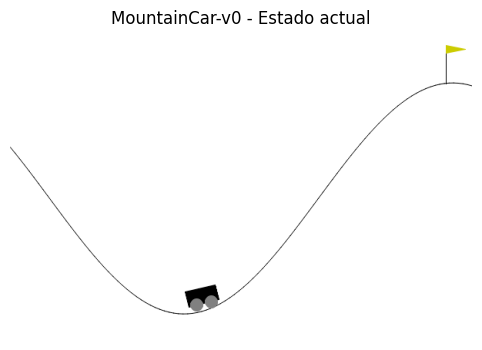

In [6]:
# Visualizamos el estado actual de MountainCar
imagen = env.render()

plt.figure(figsize=(8, 4))
plt.imshow(imagen)
plt.axis("off")
plt.title("MountainCar-v0 - Estado actual")
plt.show()

### Visualización del entorno

Utilicé **env.render()** para visualizar gráficamente el estado actual de MountainCar-v0.

En la imagen se observa el carrito ubicado cerca del fondo del valle y una bandera amarilla que representa el objetivo.

El desafío consiste en conseguir que el carrito alcance la bandera. Como no tiene suficiente potencia para subir directamente, el agente deberá aprender a desplazarse hacia ambos lados para acumular impulso.

Esta visualización permite relacionar las observaciones numéricas de posición y velocidad con el comportamiento del carrito dentro del entorno.

## Sistema de recompensas y finalización del episodio

In [7]:
# Iniciamos un nuevo episodio
estado, info = env.reset(seed=42)

recompensa_total = 0
pasos = 0
terminado = False
truncado = False

# Ejecutamos acciones aleatorias hasta finalizar el episodio
while not (terminado or truncado):

    accion = env.action_space.sample()

    estado, recompensa, terminado, truncado, info = env.step(accion)

    recompensa_total += recompensa
    pasos += 1

print("Pasos realizados:", pasos)
print("Recompensa acumulada:", recompensa_total)
print("Posición final:", round(float(estado[0]), 6))
print("Objetivo alcanzado:", terminado)
print("Límite de pasos alcanzado:", truncado)

Pasos realizados: 200
Recompensa acumulada: -200.0
Posición final: -0.535794
Objetivo alcanzado: False
Límite de pasos alcanzado: True


### Análisis de recompensas y finalización

Para comprender el sistema de recompensas, ejecuté un episodio completo utilizando acciones aleatorias.

El agente realizó **200 pasos** y obtuvo una recompensa acumulada de **-200**, ya que MountainCar aplica una penalización de **-1 por cada paso**.

El carrito terminó en una posición dentro del valle, sin alcanzar el objetivo ubicado en la posición **0.5**.

El episodio finalizó porque se alcanzó el límite de **200 pasos** (truncado = True), no porque el agente hubiera conseguido llegar a la meta (terminado = False).

Esta prueba muestra que realizar movimientos aleatorios no garantiza resolver el problema. El agente necesita aprender una estrategia que le permita acumular impulso y alcanzar la cima utilizando la menor cantidad posible de pasos.

Por eso, una recompensa acumulada menos negativa indicará un mejor desempeño: significa que el agente necesitó menos pasos para completar el objetivo, siempre que efectivamente haya llegado a la meta.

### Agente, entorno y política

En MountainCar-v0, el **agente** es quien decide qué acción realizar sobre el carrito, mientras que el **entorno** representa el escenario y responde a esas acciones.

En cada paso, el agente recibe una observación con la posición y velocidad del carrito, selecciona una acción y obtiene un nuevo estado junto con una recompensa.

La **política** es la estrategia que utiliza el agente para elegir sus acciones.

En esta primera exploración utilizamos una política aleatoria, que no aprende de la experiencia ni tiene en cuenta el estado actual.

En las siguientes secciones vamos a implementar Q-Learning y Deep Q-Network (DQN) para comprobar si el agente puede aprender una estrategia que consiga llegar a la meta.

El objetivo será comparar las tres políticas utilizando las mismas condiciones de evaluación.

## 2.2 - Función para visualizar la política

In [8]:

def visualizar_politica(politica, titulo="Política"):
    # Generamos valores de posición y velocidad
    posiciones = np.linspace(-1.2, 0.6, 50)
    velocidades = np.linspace(-0.07, 0.07, 50)

    # Guardamos la acción elegida para cada estado
    acciones = np.zeros((50, 50), dtype=int)

    for i, velocidad in enumerate(velocidades):
        for j, posicion in enumerate(posiciones):
            estado = np.array([posicion, velocidad], dtype=np.float32)
            acciones[i, j] = politica(estado)

    # Mostramos las acciones mediante colores
    plt.figure(figsize=(9, 5))
    plt.imshow(
        acciones,
        origin="lower",
        extent=[-1.2, 0.6, -0.07, 0.07],
        aspect="auto",
        cmap=plt.get_cmap("viridis", 3),
        vmin=-0.5,
        vmax=2.5
    )

    plt.colorbar(ticks=[0, 1, 2], label="Acción elegida")
    plt.xlabel("Posición")
    plt.ylabel("Velocidad")
    plt.title(titulo)
    plt.show()


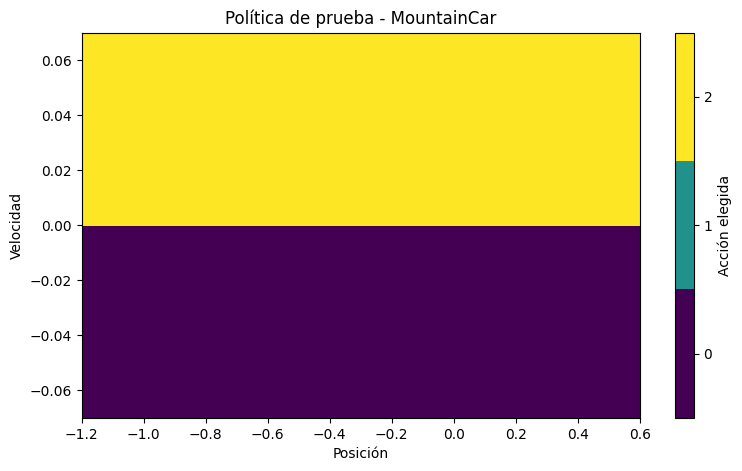

In [9]:
# Política de prueba: acelerar según el signo de la velocidad
def politica_prueba(estado):
    posicion, velocidad = estado

    if velocidad >= 0:
        return 2  # Derecha
    else:
        return 0  # Izquierda

visualizar_politica(politica_prueba, "Política de prueba - MountainCar")

### Análisis de la visualización de políticas

Implementé una función **visualizar_politica()** que permite representar gráficamente las decisiones de un agente según la posición y velocidad del carrito.

La función evalúa 2.500 combinaciones de estados (50 posiciones × 50 velocidades) y muestra mediante colores qué acción seleccionaría la política en cada caso.

Para comprobar su funcionamiento utilicé una política de prueba que acelera hacia la derecha cuando la velocidad es positiva o cero, y hacia la izquierda cuando es negativa.

El gráfico muestra dos regiones claramente diferenciadas, lo que confirma que la función representa correctamente las decisiones definidas.

Esta política es únicamente una prueba de visualización y no fue entrenada. Más adelante utilizaremos la misma función para visualizar las políticas obtenidas con Q-Learning y DQN.

## 2.3 - Entrenamiento de políticas

### 2.3.1 - Política aleatoria

In [10]:

class PoliticaAleatoria:
    """Agente que selecciona acciones sin aprender del entorno."""

    def __init__(self, n_acciones):
        self.n_acciones = n_acciones
        self.nombre = "Política Aleatoria"

    def seleccionar_accion(self, estado):
        return np.random.randint(self.n_acciones)

    def evaluar(self, env, episodios=100, semilla=3000):
        recompensas = []
        exitos = 0
        pasos_totales = []

        for episodio in range(episodios):
            estado, _ = env.reset(seed=semilla + episodio)
            recompensa_total = 0
            terminado = False
            truncado = False
            pasos = 0

            while not (terminado or truncado):
                accion = self.seleccionar_accion(estado)

                estado, recompensa, terminado, truncado, _ = env.step(accion)

                recompensa_total += recompensa
                pasos += 1

            recompensas.append(recompensa_total)
            pasos_totales.append(pasos)

            if terminado:
                exitos += 1

        tasa_exito = exitos / episodios

        print(f"Resultados de {self.nombre}")
        print(f"Tasa de éxito: {tasa_exito:.2%}")
        print(f"Recompensa promedio: {np.mean(recompensas):.2f}")
        print(f"Pasos promedio: {np.mean(pasos_totales):.2f}")

        return recompensas, tasa_exito


In [11]:

# Evaluamos la política aleatoria durante 100 episodios
np.random.seed(42)

agente_aleatorio = PoliticaAleatoria(env.action_space.n)

recompensas_aleatorio, tasa_exito_aleatorio = agente_aleatorio.evaluar(
    env,
    episodios=100
)


Resultados de Política Aleatoria
Tasa de éxito: 0.00%
Recompensa promedio: -200.00
Pasos promedio: 200.00


### 2.3.2 - Q-Learning tabular

In [12]:

# Cantidad de intervalos para posición y velocidad
n_bins = 20

# Límites definidos por el entorno
limites_inferiores = env.observation_space.low
limites_superiores = env.observation_space.high

def discretizar_estado(estado):
    # Convertimos los valores continuos en índices enteros
    proporcion = (estado - limites_inferiores) / (
        limites_superiores - limites_inferiores
    )

    indices = (proporcion * n_bins).astype(int)

    # Aseguramos índices válidos entre 0 y 19
    indices = np.clip(indices, 0, n_bins - 1)

    return tuple(indices)

# Comprobamos la discretización
estado_prueba, _ = env.reset(seed=42)

print("Estado continuo:", estado_prueba)
print("Estado discretizado:", discretizar_estado(estado_prueba))
print("Dimensiones de tabla Q:", (n_bins, n_bins, env.action_space.n))


Estado continuo: [-0.4452088  0.       ]
Estado discretizado: (np.int64(8), np.int64(10))
Dimensiones de tabla Q: (20, 20, np.int64(3))


In [13]:

class QLearningTabular:
    def __init__(self, n_bins=20, n_acciones=3,
                 alpha=0.1, gamma=0.99,
                 epsilon=1.0, epsilon_min=0.01,
                 epsilon_decay=0.999):

        # Tabla Q: posición, velocidad y acción
        self.q_table = np.zeros((n_bins, n_bins, n_acciones))

        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.n_acciones = n_acciones

    def seleccionar_accion(self, estado, entrenando=True):
        estado_discreto = discretizar_estado(estado)

        # Durante el entrenamiento exploramos con probabilidad epsilon
        if entrenando and np.random.random() < self.epsilon:
            return np.random.randint(self.n_acciones)

        # En caso contrario elegimos la mejor acción conocida
        return int(np.argmax(self.q_table[estado_discreto]))

    def entrenar(self, env, episodios=2000):
        recompensas = []
        exitos = 0

        for episodio in range(episodios):
            estado, _ = env.reset(seed=42 + episodio)
            terminado = False
            truncado = False
            recompensa_total = 0

            while not (terminado or truncado):
                estado_discreto = discretizar_estado(estado)
                accion = self.seleccionar_accion(estado)

                siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)
                siguiente_discreto = discretizar_estado(siguiente_estado)

                # Actualización de Q-Learning
                valor_actual = self.q_table[estado_discreto][accion]

                if terminado:
                    objetivo = recompensa
                else:
                    objetivo = recompensa + self.gamma * np.max(
                        self.q_table[siguiente_discreto]
                    )

                self.q_table[estado_discreto][accion] += (
                    self.alpha * (objetivo - valor_actual)
                )

                estado = siguiente_estado
                recompensa_total += recompensa

            if terminado:
                exitos += 1

            recompensas.append(recompensa_total)

            # Reducimos progresivamente la exploración
            self.epsilon = max(
                self.epsilon_min,
                self.epsilon * self.epsilon_decay
            )

            if (episodio + 1) % 1000 == 0:
                print(
                    f"Episodio {episodio + 1} | "
                    f"Recompensa promedio últimos 100: "
                    f"{np.mean(recompensas[-100:]):.2f} | "
                    f"Éxitos acumulados: {exitos}"
                )

        return recompensas


### Implementación de Q-Learning tabular

Para implementar Q-Learning en MountainCar, adapté el enfoque utilizado en el TP3 con FrozenLake.

La principal diferencia es que FrozenLake tiene estados discretos, mientras que MountainCar utiliza dos observaciones continuas: posición y velocidad.

Por este motivo, dividí cada variable en 20 intervalos, obteniendo 400 combinaciones posibles de estados. Como el agente dispone de tres acciones, la tabla Q contiene 1.200 valores.

**Funcionamiento del algoritmo**

- **Tabla Q:** almacena el valor estimado de realizar cada acción en cada estado.
- **Alpha (0.1):** controla cuánto se actualizan los valores aprendidos.
- **Gamma (0.99):** determina la importancia de las recompensas futuras.
- **Epsilon-greedy:** permite combinar exploración de acciones aleatorias con el aprovechamiento de lo aprendido.

Durante el entrenamiento, el agente selecciona acciones, observa las recompensas y actualiza la tabla Q utilizando la recompensa recibida y el valor estimado del siguiente estado.

Además, epsilon disminuye progresivamente para reducir la exploración a medida que avanza el entrenamiento.

Esta implementación conserva la lógica principal de Q-Learning del TP3, incorporando la discretización necesaria para trabajar con MountainCar.

In [14]:

# Entrenamiento del agente Q-Learning
np.random.seed(42)

agente_q = QLearningTabular(
    n_bins=20,
    n_acciones=env.action_space.n,
    alpha=0.1,
    gamma=0.99,
    epsilon=1.0,
    epsilon_min=0.01,
    epsilon_decay=0.999
)

recompensas_q = agente_q.entrenar(env, episodios=2000)

print("\nEntrenamiento finalizado")
print(f"Recompensa promedio últimos 100 episodios: {np.mean(recompensas_q[-100:]):.2f}")
print(f"Epsilon final: {agente_q.epsilon:.4f}")


Episodio 1000 | Recompensa promedio últimos 100: -200.00 | Éxitos acumulados: 0
Episodio 2000 | Recompensa promedio últimos 100: -186.47 | Éxitos acumulados: 131

Entrenamiento finalizado
Recompensa promedio últimos 100 episodios: -186.47
Epsilon final: 0.1352


In [15]:

# Evaluación de Q-Learning sin exploración
recompensas_q_eval = []
exitos_q_eval = 0

for episodio in range(100):
    estado, _ = env.reset(seed=3000 + episodio)
    terminado = False
    truncado = False
    recompensa_total = 0

    while not (terminado or truncado):
        accion = agente_q.seleccionar_accion(estado, entrenando=False)

        estado, recompensa, terminado, truncado, _ = env.step(accion)
        recompensa_total += recompensa

    recompensas_q_eval.append(recompensa_total)

    if terminado:
        exitos_q_eval += 1

tasa_exito_q = exitos_q_eval / 100

print("Evaluación Q-Learning (100 episodios)")
print(f"Tasa de éxito: {tasa_exito_q:.2%}")
print(f"Recompensa promedio: {np.mean(recompensas_q_eval):.2f}")
print(f"Pasos promedio: {-np.mean(recompensas_q_eval):.2f}")


Evaluación Q-Learning (100 episodios)
Tasa de éxito: 93.00%
Recompensa promedio: -157.18
Pasos promedio: 157.18


### Resultados de Q-Learning

Entrené el agente durante 2.000 episodios utilizando una tabla Q con 400 estados discretizados y tres acciones posibles.

Durante el entrenamiento, la recompensa promedio de los últimos 100 episodios pasó de **-200** en el episodio 1.000 a **-186,47** en el episodio 2.000. Se registraron **131 episodios exitosos**.

Para comprobar el aprendizaje, evalué la política durante 100 episodios sin exploración aleatoria, utilizando las semillas del **3000 al 3099**, diferentes de las utilizadas durante el entrenamiento.

**Resultados de evaluación:**

- Tasa de éxito: **93 %**.
- Recompensa promedio: **-157,18**.
- Pasos promedio: **157,18**.

El agente logró alcanzar la meta en **93 de los 100 episodios evaluados**, utilizando las decisiones aprendidas en la tabla Q.

En comparación con la política aleatoria, que no obtuvo ningún éxito, Q-Learning mostró una mejora importante.

La discretización permitió adaptar Q-Learning a las observaciones continuas de MountainCar, aunque implica una pérdida de precisión respecto de los valores originales de posición y velocidad.

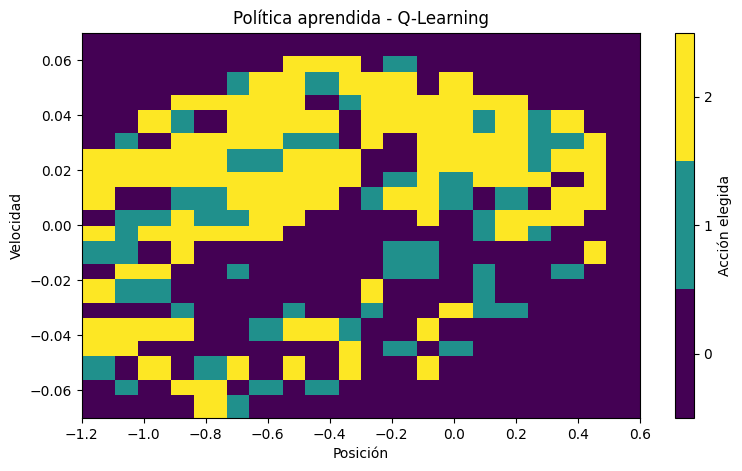

In [16]:
# Visualizamos la política aprendida por Q-Learning
visualizar_politica(
    lambda estado: agente_q.seleccionar_accion(estado, entrenando=False),
    "Política aprendida - Q-Learning"
)

### Visualización de la política Q-Learning

Utilicé la función desarrollada en el punto 2.2 para representar la política aprendida por Q-Learning después de 2.000 episodios de entrenamiento.

El gráfico muestra qué acción selecciona el agente para distintas combinaciones de posición y velocidad.

A diferencia de la política de prueba, las acciones se distribuyen en diferentes regiones del gráfico, lo que indica que el agente aprendió a tomar decisiones considerando ambas observaciones.

El patrón presenta regiones irregulares debido a la discretización de los estados y a las diferencias en la experiencia acumulada durante el entrenamiento.

La evaluación realizada mostró una tasa de éxito del 93 %, por lo que la política consiguió alcanzar la meta en 93 de los 100 episodios evaluados sin exploración aleatoria.

### 2.3.3 - Deep Q-Network (DQN)

In [17]:

class DQN(nn.Module):
    """Red neuronal para aproximar los valores Q."""

    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, output_size)
        )

    def forward(self, x):
        return self.network(x)


# Comprobamos la arquitectura para MountainCar
red_prueba = DQN(input_size=2, hidden_size=128, output_size=3)

estado_prueba = torch.tensor(
    [[-0.4452088, 0.0]], dtype=torch.float32
)

salida = red_prueba(estado_prueba)

print("Arquitectura:", red_prueba)
print("Dimensiones de salida:", salida.shape)
print("Valores Q iniciales:", salida.detach().numpy())


Arquitectura: DQN(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=3, bias=True)
  )
)
Dimensiones de salida: torch.Size([1, 3])
Valores Q iniciales: [[-0.01644429  0.19481304  0.00635532]]


### Arquitectura de la red neuronal DQN

Para implementar Deep Q-Network (DQN), utilicé una red neuronal con PyTorch, tomando como referencia la arquitectura del TP3 FrozenLake.

La principal adaptación fue cambiar la cantidad de entradas y salidas para trabajar con MountainCar.

La red recibe dos valores continuos (posición y velocidad), tiene dos capas ocultas de 128 neuronas con activación ReLU y genera tres valores Q, uno para cada acción posible.

A diferencia de Q-Learning tabular, DQN no necesita discretizar los estados, ya que la red neuronal puede procesar directamente las observaciones continuas.

Al probar la arquitectura, obtuve una salida de dimensiones **(1, 3)**, confirmando que la red produce las tres estimaciones esperadas.

Los valores Q iniciales todavía no representan una política aprendida, porque la red no fue entrenada.

In [18]:

class DQNAgent:
    def __init__(self, state_size=2, action_size=3,
                 lr=0.001, gamma=0.99, epsilon=1.0):

        self.state_size = state_size
        self.action_size = action_size
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = 0.05
        self.epsilon_decay = 0.995

        self.device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        # Red principal y red objetivo
        self.q_network = DQN(
            state_size, 128, action_size
        ).to(self.device)

        self.target_network = DQN(
            state_size, 128, action_size
        ).to(self.device)

        self.optimizer = optim.Adam(
            self.q_network.parameters(), lr=lr
        )

        self.actualizar_target()

        # Memoria de experiencias
        self.memory = deque(maxlen=10000)
        self.batch_size = 64

        # Seguimiento del entrenamiento
        self.pasos = 0
        self.frecuencia_target = 500
        self.losses = []

    def seleccionar_accion(self, estado, entrenando=True):
        # Exploración epsilon-greedy
        if entrenando and random.random() < self.epsilon:
            return random.randrange(self.action_size)

        estado_tensor = torch.as_tensor(
            estado, dtype=torch.float32,
            device=self.device
        ).unsqueeze(0)

        with torch.no_grad():
            valores_q = self.q_network(estado_tensor)

        return int(valores_q.argmax(dim=1).item())

    def recordar(self, estado, accion, recompensa,
                 siguiente_estado, terminado):

        self.memory.append((
            np.array(estado, dtype=np.float32),
            accion,
            recompensa,
            np.array(siguiente_estado, dtype=np.float32),
            terminado
        ))

    def replay(self):
        if len(self.memory) < self.batch_size:
            return

        # Seleccionamos experiencias anteriores
        batch = random.sample(self.memory, self.batch_size)

        estados = torch.as_tensor(
            np.stack([e[0] for e in batch]),
            dtype=torch.float32, device=self.device
        )
        acciones = torch.tensor(
            [e[1] for e in batch],
            dtype=torch.long, device=self.device
        )
        recompensas = torch.tensor(
            [e[2] for e in batch],
            dtype=torch.float32, device=self.device
        )
        siguientes_estados = torch.as_tensor(
            np.stack([e[3] for e in batch]),
            dtype=torch.float32, device=self.device
        )
        terminados = torch.tensor(
            [e[4] for e in batch],
            dtype=torch.float32, device=self.device
        )

        # Valores Q actuales de las acciones realizadas
        valores_actuales = self.q_network(estados).gather(
            1, acciones.unsqueeze(1)
        ).squeeze(1)

        # Valores Q objetivo
        with torch.no_grad():
            valores_siguientes = self.target_network(
                siguientes_estados
            ).max(dim=1).values

            objetivos = recompensas + (
                self.gamma * valores_siguientes * (1 - terminados)
            )

        # Actualizamos la red principal
        perdida = F.smooth_l1_loss(valores_actuales, objetivos)

        self.optimizer.zero_grad()
        perdida.backward()
        self.optimizer.step()

        self.losses.append(perdida.item())

        self.pasos += 1

        if self.pasos % self.frecuencia_target == 0:
            self.actualizar_target()

    def actualizar_target(self):
        self.target_network.load_state_dict(
            self.q_network.state_dict()
        )

    def reducir_epsilon(self):
        self.epsilon = max(
            self.epsilon_min,
            self.epsilon * self.epsilon_decay
        )


In [19]:
agente_dqn = DQNAgent(
    state_size=2,
    action_size=3
)

print("Dispositivo:", agente_dqn.device)
print("Capacidad de memoria:", agente_dqn.memory.maxlen)
print("Tamaño de lote:", agente_dqn.batch_size)
print("Epsilon inicial:", agente_dqn.epsilon)

Dispositivo: cpu
Capacidad de memoria: 10000
Tamaño de lote: 64
Epsilon inicial: 1.0


### Implementación del agente DQN

Para entrenar la red neuronal implementé la clase **DQNAgent**, adaptando los mecanismos utilizados en el TP3 FrozenLake.

El agente utiliza dos redes neuronales: una principal, que aprende a estimar los valores Q, y una red objetivo (*Target Network*), que proporciona referencias más estables durante el entrenamiento.

También utiliza *Experience Replay*, que almacena hasta 10.000 experiencias anteriores. Durante el aprendizaje se seleccionan lotes aleatorios de 64 experiencias para actualizar la red principal.

La selección de acciones utiliza la estrategia *epsilon-greedy*, comenzando con exploración aleatoria y reduciéndola progresivamente.

Las principales adaptaciones respecto de FrozenLake fueron utilizar directamente las observaciones continuas de MountainCar, configurar tres acciones de salida y distinguir la finalización del episodio del truncamiento por límite de pasos.

La verificación inicial confirmó que el agente se creó correctamente, utilizando CPU, una memoria de 10.000 experiencias, lotes de 64 y epsilon inicial de 1.

In [20]:

# Entrenamiento del agente DQN
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Creamos un agente nuevo para comenzar desde cero
agente_dqn = DQNAgent(state_size=2, action_size=3)

recompensas_dqn = []
exitos_dqn = 0

# Igualamos la cantidad de episodios con Q-Learning
episodios_dqn = 2000

for episodio in range(episodios_dqn):
    estado, _ = env.reset(seed=42 + episodio)

    terminado = False
    truncado = False
    recompensa_total = 0

    while not (terminado or truncado):
        # Seleccionamos una acción
        accion = agente_dqn.seleccionar_accion(estado)

        # Interactuamos con MountainCar
        siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

        # Guardamos la experiencia
        agente_dqn.recordar(
            estado, accion, recompensa, siguiente_estado, terminado
        )

        # Entrenamos la red con experiencias anteriores
        agente_dqn.replay()

        estado = siguiente_estado
        recompensa_total += recompensa

    if terminado:
        exitos_dqn += 1

    recompensas_dqn.append(recompensa_total)

    # Reducimos la exploración al terminar cada episodio
    agente_dqn.reducir_epsilon()

    # Mostramos resultados cada 500 episodios
    if (episodio + 1) % 500 == 0:
        print(
            f"Episodio {episodio + 1} | "
            f"Recompensa promedio últimos 100: "
            f"{np.mean(recompensas_dqn[-100:]):.2f} | "
            f"Éxitos acumulados: {exitos_dqn} | "
            f"Epsilon: {agente_dqn.epsilon:.3f}"
        )

print("\nEntrenamiento DQN finalizado")
print(f"Éxitos acumulados: {exitos_dqn}")
print(f"Recompensa promedio últimos 100: {np.mean(recompensas_dqn[-100:]):.2f}")
print(f"Epsilon final: {agente_dqn.epsilon:.4f}")


Episodio 500 | Recompensa promedio últimos 100: -200.00 | Éxitos acumulados: 0 | Epsilon: 0.082
Episodio 1000 | Recompensa promedio últimos 100: -200.00 | Éxitos acumulados: 0 | Epsilon: 0.050
Episodio 1500 | Recompensa promedio últimos 100: -200.00 | Éxitos acumulados: 0 | Epsilon: 0.050
Episodio 2000 | Recompensa promedio últimos 100: -200.00 | Éxitos acumulados: 0 | Epsilon: 0.050

Entrenamiento DQN finalizado
Éxitos acumulados: 0
Recompensa promedio últimos 100: -200.00
Epsilon final: 0.0500


In [21]:

# Evaluación de DQN sin exploración
recompensas_dqn_eval = []
exitos_dqn_eval = 0

agente_dqn.q_network.eval()

for episodio in range(100):
    estado, _ = env.reset(seed=3000 + episodio)
    terminado = False
    truncado = False
    recompensa_total = 0

    while not (terminado or truncado):
        accion = agente_dqn.seleccionar_accion(
            estado, entrenando=False
        )

        estado, recompensa, terminado, truncado, _ = env.step(accion)
        recompensa_total += recompensa

    recompensas_dqn_eval.append(recompensa_total)

    if terminado:
        exitos_dqn_eval += 1

tasa_exito_dqn = exitos_dqn_eval / 100

print("Evaluación DQN (100 episodios)")
print(f"Tasa de éxito: {tasa_exito_dqn:.2%}")
print(f"Recompensa promedio: {np.mean(recompensas_dqn_eval):.2f}")
print(f"Pasos promedio: {-np.mean(recompensas_dqn_eval):.2f}")


Evaluación DQN (100 episodios)
Tasa de éxito: 0.00%
Recompensa promedio: -200.00
Pasos promedio: 200.00


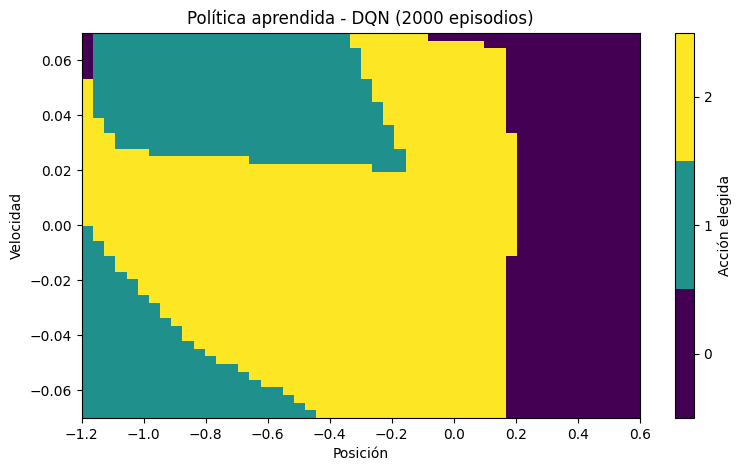

In [22]:
# Visualizamos la política aprendida por DQN
visualizar_politica(
    lambda estado: agente_dqn.seleccionar_accion(
        estado, entrenando=False
    ),
    "Política aprendida - DQN (2000 episodios)"
)

### Resultados y análisis de DQN

Entrené el agente DQN durante 2.000 episodios, utilizando la arquitectura de dos capas ocultas de 128 neuronas, Experience Replay y Target Network.

Para mantener una comparación más equilibrada con Q-Learning, utilicé la misma cantidad de episodios de entrenamiento y posteriormente evalué ambas políticas durante 100 episodios con las mismas semillas y sin exploración aleatoria.

**Resultados obtenidos:**

- Episodios de entrenamiento: 2.000.
- Éxitos durante el entrenamiento: 0.
- Recompensa promedio de los últimos 100 episodios: -200.
- Epsilon final: 0.05.
- Tasa de éxito en evaluación: 0 %.
- Recompensa promedio en evaluación: -200.
- Pasos promedio: 200.

Al visualizar la política observé que la red neuronal distingue diferentes regiones del espacio de estados, seleccionando acciones según la posición y velocidad del carrito.

Sin embargo, estas decisiones no fueron suficientes para alcanzar la meta durante los episodios evaluados.

**Análisis de las dificultades**

Una posible explicación es que epsilon disminuyó rápidamente hasta su valor mínimo de 0.05, reduciendo la exploración antes de encontrar una estrategia efectiva.

Además, MountainCar presenta una recompensa de -1 por cada paso, lo que dificulta distinguir qué movimientos favorecen la acumulación de impulso cuando el agente todavía no alcanza el objetivo.

Estos resultados no demuestran que DQN sea inferior a Q-Learning en general, sino que la configuración utilizada no logró aprender una política exitosa en este experimento.

## 2.4 - Comparación del desempeño de las políticas

In [23]:

import pandas as pd

# Resultados de las tres políticas evaluadas
resultados = pd.DataFrame({
    "Política": ["Aleatoria", "Q-Learning", "DQN"],
    "Episodios entrenamiento": [0, 2000, 2000],
    "Episodios evaluación": [100, 100, 100],
    "Tasa de éxito (%)": [
        tasa_exito_aleatorio * 100,
        tasa_exito_q * 100,
        tasa_exito_dqn * 100
    ],
    "Recompensa promedio": [
        np.mean(recompensas_aleatorio),
        np.mean(recompensas_q_eval),
        np.mean(recompensas_dqn_eval)
    ],
    "Pasos promedio": [
        -np.mean(recompensas_aleatorio),
        -np.mean(recompensas_q_eval),
        -np.mean(recompensas_dqn_eval)
    ]
})

display(resultados.round(2))


,Política,Episodios entrenamiento,Episodios evaluación,Tasa de éxito (%),Recompensa promedio,Pasos promedio
0,Aleatoria,0,100,0.0,-200.00,200.00
1,Q-Learning,2000,100,93.0,-157.18,157.18
2,DQN,2000,100,0.0,-200.00,200.00


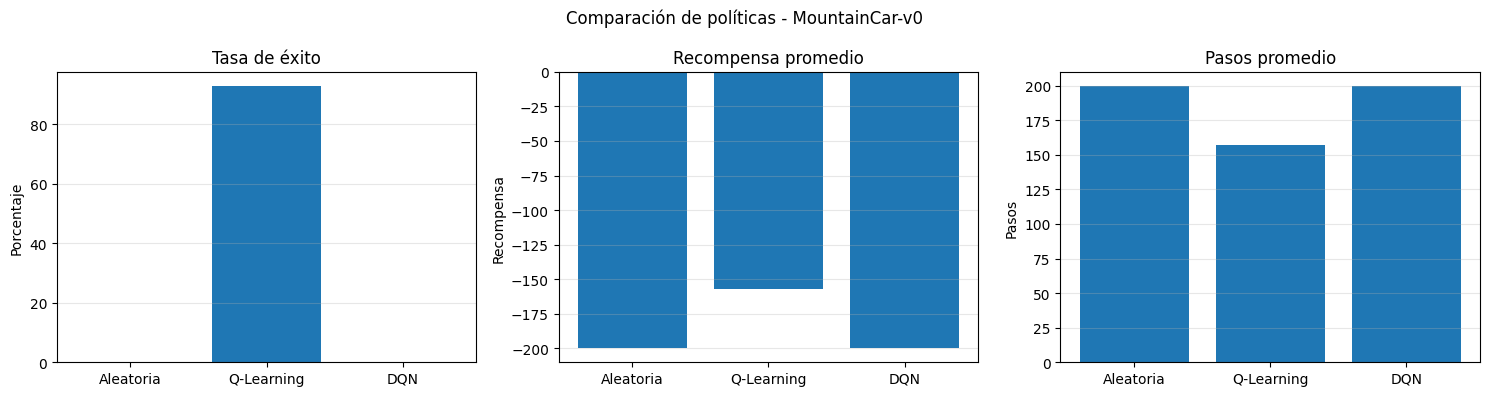

In [24]:

# Comparación gráfica de las tres políticas
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metricas = [
    ("Tasa de éxito (%)", "Tasa de éxito", "Porcentaje"),
    ("Recompensa promedio", "Recompensa promedio", "Recompensa"),
    ("Pasos promedio", "Pasos promedio", "Pasos")
]

for ax, (columna, titulo, etiqueta) in zip(axes, metricas):
    ax.bar(resultados["Política"], resultados[columna])
    ax.set_title(titulo)
    ax.set_ylabel(etiqueta)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Comparación de políticas - MountainCar-v0")
plt.tight_layout()
plt.show()


### Análisis comparativo de las políticas

Para comparar el desempeño de las tres políticas, realicé una evaluación de 100 episodios por agente, utilizando las mismas semillas de inicialización (3000 a 3099), diferentes de las utilizadas durante el entrenamiento.

Entrené Q-Learning y DQN durante **2.000 episodios cada uno**, para mantener la misma cantidad de episodios de entrenamiento.

**Resultados principales:**

- **Política aleatoria:** no alcanzó la meta en ningún episodio, con una recompensa promedio de **-200**.
- **Q-Learning:** obtuvo una tasa de éxito del **93 %**, una recompensa promedio de **-157,18** y necesitó aproximadamente **157 pasos por episodio**.
- **DQN:** obtuvo una tasa de éxito del **0 %**, con una recompensa promedio de **-200**, sin conseguir alcanzar la meta.

Q-Learning fue el algoritmo con mejor desempeño en este experimento. La discretización de posición y velocidad permitió aprender una estrategia efectiva utilizando una tabla Q.

En cambio, DQN no consiguió aprender una política exitosa con la arquitectura y los hiperparámetros utilizados, aunque su red neuronal distinguió diferentes regiones del espacio de estados.

**Interpretación**

Los resultados muestran que utilizar una red neuronal no garantiza automáticamente un mejor desempeño. En este problema, Q-Learning obtuvo mejores resultados con la configuración utilizada.

Sin embargo, esta comparación no demuestra que Q-Learning sea superior a DQN en general. Aunque ambos utilizaron 2.000 episodios, tienen diferentes mecanismos de aprendizaje y costos computacionales.

La experiencia demuestra la importancia de evaluar los modelos experimentalmente, analizar sus resultados y justificar las decisiones de implementación.

## 2.5 - Conclusiones, experiencia y referencias

### Conclusiones y experiencia personal

En este trabajo adapté el notebook del TP3 FrozenLake al entorno MountainCar-v0 para implementar y comparar tres políticas de aprendizaje por refuerzo: aleatoria, Q-Learning tabular y Deep Q-Network (DQN).

Una de las principales diferencias que encontré fue la representación de los estados. Mientras que FrozenLake utiliza estados discretos, MountainCar trabaja con posición y velocidad continuas. Para resolverlo, utilicé una discretización de 20 intervalos por variable en Q-Learning, mientras que en DQN procesé directamente las observaciones con una red neuronal.

**Resultados obtenidos**

Después de entrenar Q-Learning y DQN durante **2.000 episodios cada uno**, evalué las tres políticas durante 100 episodios utilizando las mismas semillas de inicialización (3000 a 3099), diferentes de las utilizadas durante el entrenamiento.

Q-Learning obtuvo el mejor resultado, con una tasa de éxito del **93 %** y una recompensa promedio de **-157,18**. En cambio, la política aleatoria y DQN no consiguieron alcanzar la meta y finalizaron con una recompensa promedio de **-200**.

**Dificultades encontradas**

La principal dificultad fue conseguir que DQN aprendiera una estrategia efectiva. Aunque la red se entrenó y generó decisiones diferentes según el estado, no logró resolver el entorno con la configuración utilizada.

Una posible causa es la reducción de epsilon durante el entrenamiento, que disminuyó la exploración antes de que el agente encontrara una estrategia exitosa. También influyó la dificultad del entorno, donde las recompensas son negativas por cada paso y no indican directamente qué movimiento permite acumular más impulso.

Otra decisión importante fue igualar la cantidad de episodios de entrenamiento entre Q-Learning y DQN para lograr una comparación más equilibrada. De todos modos, ambos algoritmos tienen diferentes costos computacionales y mecanismos de aprendizaje.

**Reflexión final**

Este trabajo me permitió comprender mejor las diferencias entre una tabla Q y una red neuronal que aproxima valores Q.

También comprobé que implementar un algoritmo más complejo no garantiza obtener mejores resultados. En nuestro experimento, Q-Learning fue más efectivo que DQN, pero esto no significa que sea superior en todos los problemas.

Me llevo principalmente la importancia de adaptar los algoritmos al entorno, controlar las condiciones de evaluación e interpretar los resultados, incluso cuando un modelo no consigue el desempeño esperado.

### Referencias

**Documentación oficial**

1. **Gymnasium — MountainCar-v0.** Descripción del entorno, espacios de observación y acción, recompensas y condiciones de finalización.  
   https://gymnasium.farama.org/environments/classic_control/mountain_car/

2. **Gymnasium — Basic Usage.** Creación de entornos e interacción mediante **reset()**, **step()** y **render()**.  
   https://gymnasium.farama.org/introduction/basic_usage/

3. **PyTorch — Reinforcement Learning (DQN) Tutorial.** Referencia para la implementación de redes DQN, Experience Replay, Target Network y entrenamiento mediante PyTorch.  
   https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning.html

**Material de referencia de la materia**

4. **TP3 RL1 — FrozenLake.** Notebook utilizado como base para adaptar las políticas de aprendizaje por refuerzo al entorno MountainCar-v0.

**Uso de inteligencia artificial**

Utilicé ChatGPT como herramienta de asistencia para adaptar el código del TP3, revisar las implementaciones, interpretar resultados y organizar la documentación.

Las decisiones de configuración, las ejecuciones y la comparación de resultados se realizaron durante el desarrollo del trabajo en Google Colab, revisando el comportamiento de cada implementación.